# Trajectories and win counts

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# here change the correct path
models_folder  = "/Users/tiesdilling/Desktop/University of Twente/Thesis/Coding/4. Python code/Models"
results_folder = "/Users/tiesdilling/Desktop/University of Twente/Thesis/Coding/4. Python code/Analysis/1. Active/Analysis/trajectories_and_wins_analysis"
os.makedirs(results_folder, exist_ok=True)

# model name: (folder, end of the file name)
models = {
    "Chronos2":    ("Chronos2", "chronos"),
    "ChronosBOLT": ("ChronosBOLT", "chronos_bolt"),
    "Moirai":      ("Moirai", "moirai"),
    "TimesFM":     ("TimesFM", "times_fm"),
}
context_lengths = [32, 64, 128, 256, 512]
walk_column = "walk_id"      # the column that says which walk a row belongs to

# read all prediction files into one table
tables = []
for model_name, (folder, file_end) in models.items():
    for L in context_lengths:
        file_path = f"{models_folder}/{folder}/predicitons_{L}_{file_end}.csv"
        predictions = pd.read_csv(file_path)
        predictions["model"] = model_name
        predictions["L"] = L
        tables.append(predictions)

data = pd.concat(tables, ignore_index=True)
data["snr"] = data["snr"].round(6)       


# the plug-in forecast is horizon * context drift, so the context drift is plugin / horizon
data["context_drift"] = data["plugin"] / data["horizon"]

cell_columns = ["model", "L", "snr", "horizon"]    # one cell = all walks with the same settings
model_names = list(models)
print(data.shape)
data.head()

(64000000, 22)


,Unnamed: 0,walk_id,snr,seed,sigma,mu,context_len,horizon,model,checkpoint,...,naive,plugin,conditional,se_model,se_naive,se_plugin,se_conditional,L,num_samples,context_drift
0,0,snr0.01_seed0,0.01,0,1.0,0.01,32,1,Chronos2,chronos-2-amazon,...,0.0,-0.023217,0.01,0.004846,0.023383,0.031022,0.020424,32,NaN,-0.023217
1,1,snr0.01_seed0,0.01,0,1.0,0.01,32,2,Chronos2,chronos-2-amazon,...,0.0,-0.046434,0.02,0.244420,0.145195,0.111964,0.160836,32,NaN,-0.023217
2,2,snr0.01_seed0,0.01,0,1.0,0.01,32,3,Chronos2,chronos-2-amazon,...,0.0,-0.069650,0.03,0.367308,0.254516,0.189090,0.285686,32,NaN,-0.023217
3,3,snr0.01_seed0,0.01,0,1.0,0.01,32,4,Chronos2,chronos-2-amazon,...,0.0,-0.092867,0.04,0.537184,0.645413,0.803252,0.582743,32,NaN,-0.023217
4,4,snr0.01_seed0,0.01,0,1.0,0.01,32,5,Chronos2,chronos-2-amazon,...,0.0,-0.116084,0.05,0.042312,0.023853,0.001471,0.041797,32,NaN,-0.023217


In [3]:
# who wins per walk and horizon (Appendix C):
# the model wins only if it is strictly better than both, a tie between plug-in and naive goes to the plug-in
se_model  = (data["forecast"] - data["actual"]) ** 2
se_plugin = (data["plugin"]   - data["actual"]) ** 2
se_naive  = (data["naive"]    - data["actual"]) ** 2

data["model_wins"]  = (se_model < se_plugin) & (se_model < se_naive)
data["plugin_wins"] = (~data["model_wins"]) & (se_plugin <= se_naive)
data["naive_wins"]  = (~data["model_wins"]) & (~data["plugin_wins"])

# share of walks each forecaster wins in a cell
win_table = data.groupby(cell_columns)[["model_wins", "plugin_wins", "naive_wins"]].mean().reset_index()

win_table.to_csv(f"{results_folder}/win_shares.csv", index=False)
win_table

,model,L,snr,horizon,model_wins,plugin_wins,naive_wins
0,Chronos2,32,0.01,1,0.42,0.31,0.27
1,Chronos2,32,0.01,2,0.34,0.35,0.31
2,Chronos2,32,0.01,3,0.28,0.42,0.30
3,Chronos2,32,0.01,4,0.35,0.38,0.27
4,Chronos2,32,0.01,5,0.30,0.35,0.35
...,...,...,...,...,...,...,...
639995,TimesFM,512,5.00,252,0.08,0.92,0.00
639996,TimesFM,512,5.00,253,0.09,0.91,0.00
639997,TimesFM,512,5.00,254,0.08,0.92,0.00
639998,TimesFM,512,5.00,255,0.09,0.91,0.00


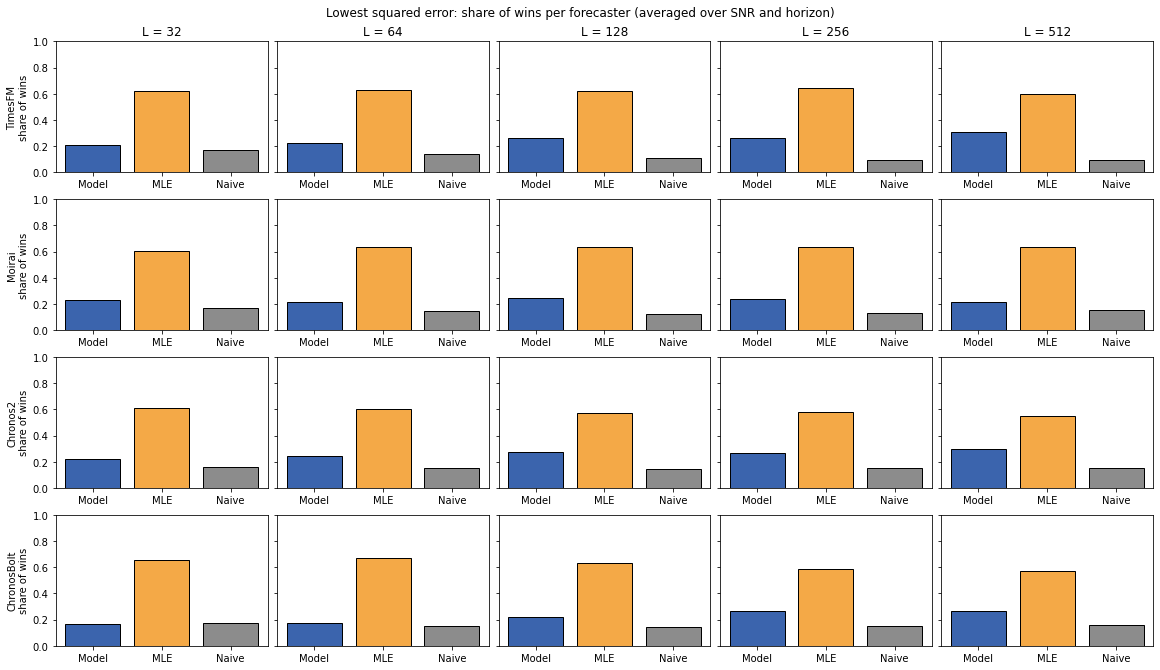


Model wins (%)
L             32    64    128   256   512
model                                    
TimesFM      21.1  22.5  26.5  26.3  30.4
Moirai       22.8  21.9  24.2  23.6  21.2
Chronos2     22.4  24.5  27.6  26.9  29.8
ChronosBOLT  16.9  17.7  21.8  26.4  26.8

MLE plug-in wins (%)
L             32    64    128   256   512
model                                    
TimesFM      61.9  63.2  62.3  64.1  60.2
Moirai       60.6  63.7  63.5  63.7  63.6
Chronos2     61.3  60.5  57.6  57.9  55.0
ChronosBOLT  65.6  66.9  63.6  58.9  57.4

Naive wins (%)
L             32    64    128   256   512
model                                    
TimesFM      17.0  14.2  11.2   9.5   9.4
Moirai       16.6  14.4  12.4  12.7  15.2
Chronos2     16.4  15.0  14.8  15.1  15.2
ChronosBOLT  17.5  15.4  14.6  14.8  15.9


In [4]:
# Win counts: share of the (walk, horizon) pairs each forecaster wins, per model and L
model_order = ["TimesFM", "Moirai", "Chronos2", "ChronosBOLT"]
model_labels = {"TimesFM": "TimesFM", "Moirai": "Moirai", "Chronos2": "Chronos2", "ChronosBOLT": "ChronosBolt"}
win_columns = ["model_wins", "plugin_wins", "naive_wins"]
win_names = ["Model", "MLE", "Naive"]
win_colors = ["#3b64ad", "#f4a947", "#8c8c8c"]

# averaged over SNR and horizon
win_share = data.groupby(["model", "L"])[win_columns].mean()

fig, axes = plt.subplots(len(model_order), len(context_lengths),
                         figsize=(3.2 * len(context_lengths), 2.3 * len(model_order)),
                         sharey=True, constrained_layout=True, squeeze=False)

for row, model_name in enumerate(model_order):
    for col, L in enumerate(context_lengths):
        ax = axes[row, col]
        ax.bar(win_names, win_share.loc[(model_name, L)].to_numpy(), color=win_colors, edgecolor="black")
        ax.set_ylim(0, 1)
        if row == 0:
            ax.set_title(f"L = {L}")
        if col == 0:
            ax.set_ylabel(f"{model_labels[model_name]}\nshare of wins")

fig.suptitle("Lowest squared error: share of wins per forecaster (averaged over SNR and horizon)")
fig.savefig(f"{results_folder}/win_bars_per_L.png", dpi=200, bbox_inches="tight")
plt.show()

# the same numbers as a table, in percent, one row per model and one column per L
win_percent = (win_share * 100).reset_index()
win_percent.to_csv(f"{results_folder}/win_percent.csv", index=False)

for column, name in zip(win_columns, ["Model", "MLE plug-in", "Naive"]):
    print(f"\n{name} wins (%)")
    table = win_percent.pivot(index="model", columns="L", values=column).reindex(model_order)
    print(table.round(1).to_string())

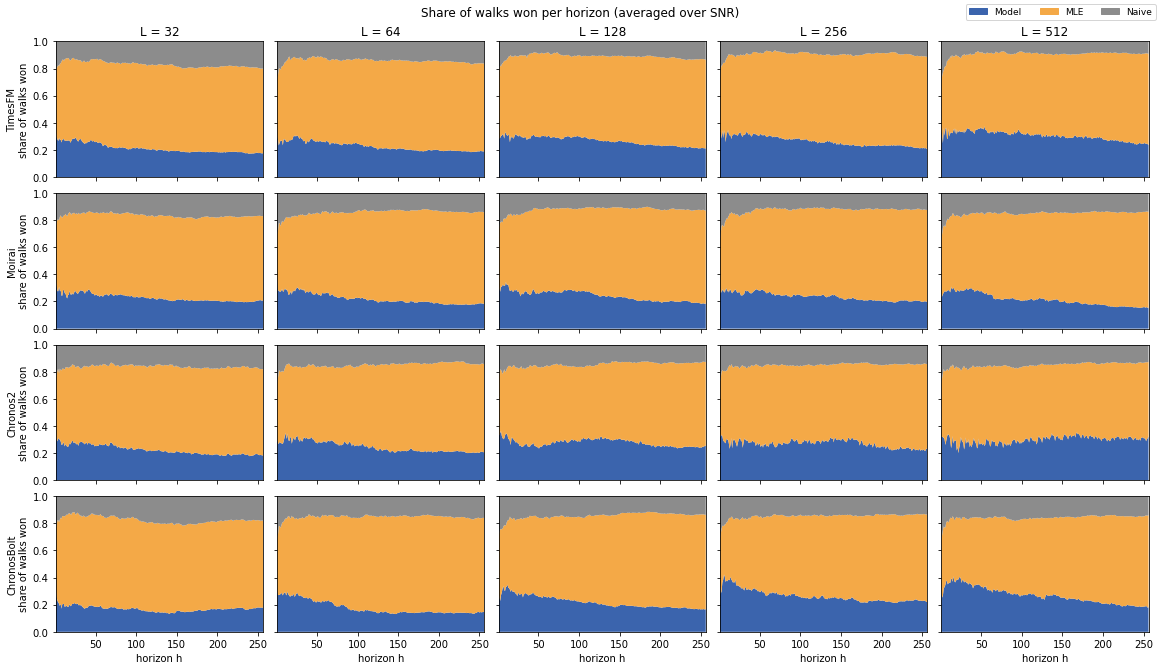

In [5]:
# Share of walks won at each horizon, averaged over SNR
win_per_horizon = win_table.groupby(["model", "L", "horizon"])[win_columns].mean()

fig, axes = plt.subplots(len(model_order), len(context_lengths),
                         figsize=(3.2 * len(context_lengths), 2.3 * len(model_order)),
                         sharex=True, sharey=True, constrained_layout=True, squeeze=False)

for row, model_name in enumerate(model_order):
    for col, L in enumerate(context_lengths):
        part = win_per_horizon.loc[(model_name, L)]

        ax = axes[row, col]
        ax.stackplot(part.index, part["model_wins"], part["plugin_wins"], part["naive_wins"], colors=win_colors)
        ax.set_xlim(part.index.min(), part.index.max())
        ax.set_ylim(0, 1)
        if row == 0:
            ax.set_title(f"L = {L}")
        if col == 0:
            ax.set_ylabel(f"{model_labels[model_name]}\nshare of walks won")
        if row == len(model_order) - 1:
            ax.set_xlabel("horizon h")

legend_boxes = [plt.Rectangle((0, 0), 1, 1, color=color) for color in win_colors]
fig.legend(legend_boxes, win_names, loc="upper right", ncol=3, fontsize=9)
fig.suptitle("Share of walks won per horizon (averaged over SNR)")
fig.savefig(f"{results_folder}/win_shares_per_L.png", dpi=200, bbox_inches="tight")
plt.show()

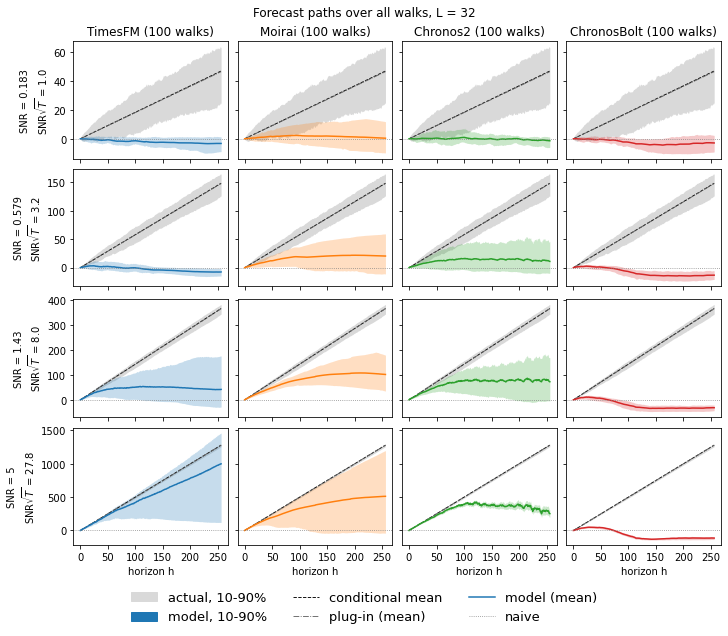

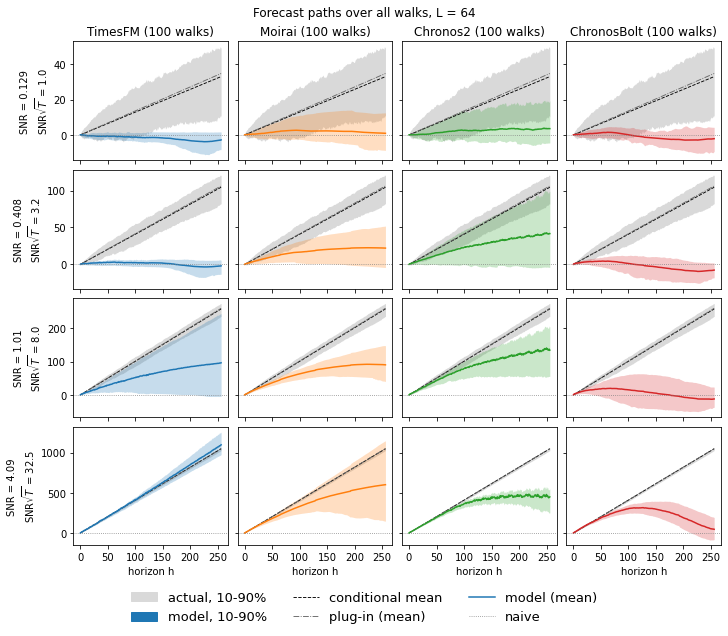

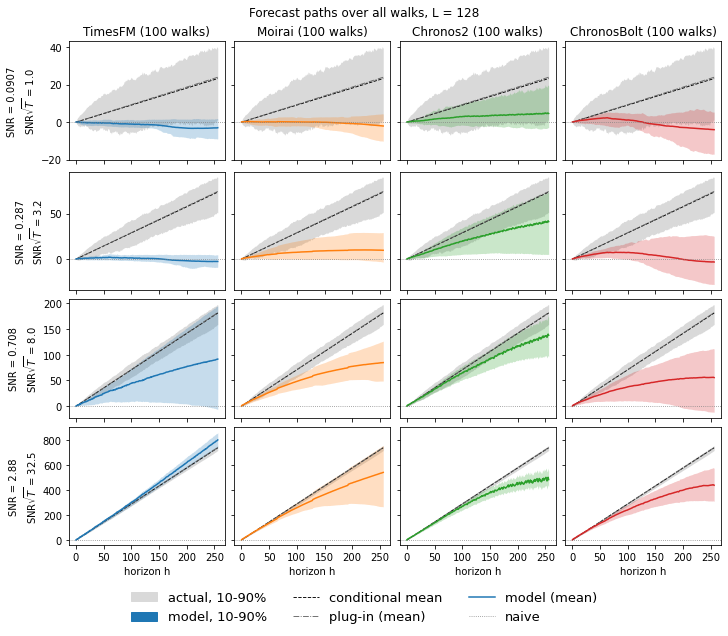

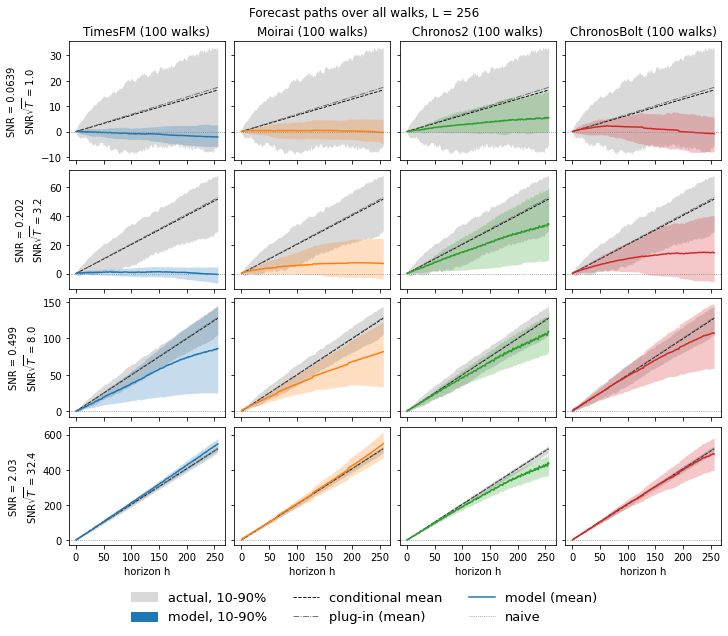

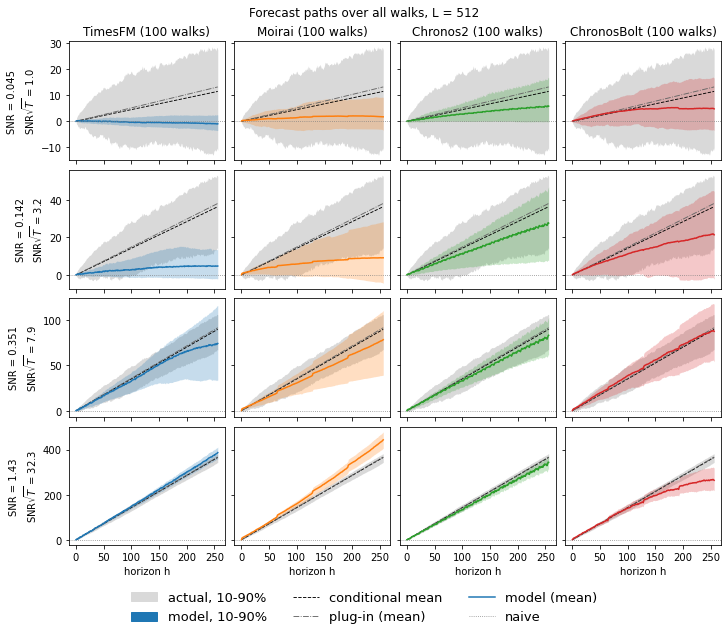

In [6]:
# Forecast paths over the 100 walks, one figure per context length
from matplotlib.lines import Line2D

path_colors = {"TimesFM": "#1f77b4", "Moirai": "#ff7f0e", "Chronos2": "#2ca02c", "ChronosBOLT": "#d62728"}
row_targets = [1, 3.2, 8, 32]          # SNR*sqrt(T) of the four rows
snr_grid = np.array(sorted(data["snr"].unique()))


def path_summary(part, column):
    """10% quantile, 90% quantile and mean over the walks at every horizon.
    All values are measured from the last context point, so every path starts at 0 at h = 0."""
    by_horizon = part.groupby("horizon")[column]
    summary = pd.DataFrame({"low": by_horizon.quantile(0.1),
                            "high": by_horizon.quantile(0.9),
                            "mean": by_horizon.mean()})
    start = pd.DataFrame({"low": [0.0], "high": [0.0], "mean": [0.0]}, index=[0])
    return pd.concat([start, summary])


legend_items = [
    plt.Rectangle((0, 0), 1, 1, color="0.85", label="actual, 10-90%"),
    plt.Rectangle((0, 0), 1, 1, color=path_colors["TimesFM"], label="model, 10-90%"),
    Line2D([], [], color="black", linestyle="--", linewidth=0.9, label="conditional mean"),
    Line2D([], [], color="0.4", linestyle="-.", linewidth=0.9, label="plug-in (mean)"),
    Line2D([], [], color=path_colors["TimesFM"], linewidth=1.5, label="model (mean)"),
    Line2D([], [], color="0.5", linestyle=":", linewidth=0.8, label="naive"),
]

for L in context_lengths:
    T = L - 1
    # the grid SNR closest to each target; at L = 32 the last row is capped at SNR = 5
    row_snrs = [snr_grid[np.argmin(np.abs(np.log(snr_grid) - np.log(target / np.sqrt(T))))]
                for target in row_targets]
    part_L = data[(data["L"] == L) & (data["snr"].isin(row_snrs))]

    fig, axes = plt.subplots(len(row_snrs), len(model_order), figsize=(10, 8),
                             sharex=True, sharey="row", constrained_layout=True, squeeze=False)

    for row, snr in enumerate(row_snrs):
        for col, model_name in enumerate(model_order):
            part = part_L[(part_L["model"] == model_name) & (part_L["snr"] == snr)]
            actual = path_summary(part, "actual")
            model = path_summary(part, "forecast")
            conditional = path_summary(part, "conditional")
            plugin = path_summary(part, "plugin")
            color = path_colors[model_name]

            ax = axes[row, col]
            ax.fill_between(actual.index, actual["low"], actual["high"], color="0.85", linewidth=0)
            ax.fill_between(model.index, model["low"], model["high"], color=color, alpha=0.25, linewidth=0)
            ax.plot(conditional.index, conditional["mean"], color="black", linestyle="--", linewidth=0.9)
            ax.plot(plugin.index, plugin["mean"], color="0.4", linestyle="-.", linewidth=0.9)
            ax.plot(model.index, model["mean"], color=color, linewidth=1.5)
            ax.axhline(0, color="0.5", linestyle=":", linewidth=0.8)
            ax.set_xticks([0, 50, 100, 150, 200, 250])
            if row == 0:
                ax.set_title(f"{model_labels[model_name]} ({part[walk_column].nunique()} walks)")
            if col == 0:
                ax.set_ylabel(f"SNR = {snr:.3g}\nSNR$\\sqrt{{T}}$ = {snr * np.sqrt(T):.1f}")
            if row == len(row_snrs) - 1:
                ax.set_xlabel("horizon h")

    fig.suptitle(f"Forecast paths over all walks, L = {L}")
    fig.legend(handles=legend_items, loc="upper center", bbox_to_anchor=(0.5, 0), ncol=3,
               frameon=False, fontsize=13)
    fig.savefig(f"{results_folder}/fig_paths_L{L}.png", dpi=200, bbox_inches="tight")
    plt.show()